TOMORROW FZ1289 FORECAST: 129 pax
OPTIMAL PRICE: 350
EXPECTED REVENUE: 45150


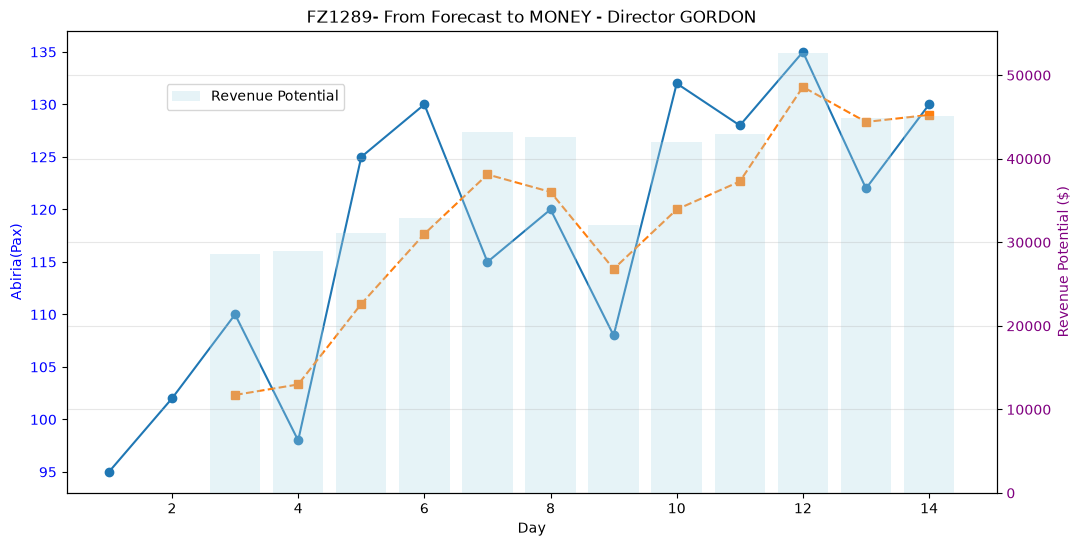


---Final RM TABLE---
    day  passengers  forecast_3day  optimal_price  forecast_revenue
7     8         120     121.666667            350      42583.333333
8     9         108     114.333333            280      32013.333333
9    10         132     120.000000            350      42000.000000
10   11         128     122.666667            350      42933.333333
11   12         135     131.666667            400      52666.666667
12   13         122     128.333333            350      44916.666667
13   14         130     129.000000            350      45150.000000


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

demand = [95, 102, 110, 98, 125, 130, 115, 120, 108, 132, 128, 135, 122, 130]
df = pd. DataFrame({'day': range(1,15), 'passengers': demand, })
df['forecast_3day']= df['passengers'].rolling(3).mean()

def pricing_engine(forecast):
    if forecast >= 130:
        return 400
    elif forecast >= 120:
        return 350
    elif forecast >= 100:
        return 280
    else:
        return 220
df['optimal_price'] = df['forecast_3day'].apply(pricing_engine)
df['forecast_revenue'] = df['forecast_3day'] * df['optimal_price']

tomorrow_forecast = df['forecast_3day'].iloc[-1]
tomorrow_price = pricing_engine(tomorrow_forecast)

print(f"TOMORROW FZ1289 FORECAST: {tomorrow_forecast:.0f} pax")
print(f"OPTIMAL PRICE: {tomorrow_price}")
print(f"EXPECTED REVENUE: {tomorrow_forecast * tomorrow_price:.0f}")

fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.set_xlabel('Day')
ax1.set_ylabel('Abiria(Pax)', color='blue')
ax1.plot( df['day'], df['passengers'], 'o-', label='Actual Demand')
ax1.plot( df['day'], df['forecast_3day'], 's--', label='Forecast')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
ax2.set_ylabel('Revenue Potential ($)', color= 'purple')
ax2.bar( df['day'], df['forecast_revenue'],color='lightblue', alpha=0.3, label='Revenue Potential')
ax2.tick_params(axis='y', labelcolor='purple')

plt.title('FZ1289- From Forecast to MONEY - Director GORDON')
plt.legend(loc='upper left', bbox_to_anchor=(0.1,0.9))
plt.grid(True, alpha=0.3)
plt.show()

print("\n---Final RM TABLE---")
print(df.tail(7)[['day', 'passengers', 'forecast_3day', 'optimal_price', 'forecast_revenue']])           
                
                
